In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
latitude = [30,60]
mask = '05'      # '01', '05': hourly > 0.1 / 0.5 mm (with the CESM2-LE ensemble) | '1': daily > 1 mm (no CESM2)

# CESM2-LE hourly ensemble (10 members), historical output of cesm2_hourly_precip_cover_calc.py (variable wet_sea_pct)
CESM2_DIR       = '/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_ens_hourly'
CESM2_THRESHOLD = {'01': 0.1, '05': 0.5}   # mm per hour, for each mask
CESM2_YEARS     = (1850, 2014)             # inclusive


In [5]:
if mask == '1':
    ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_on_1_sea_30-60N_precip_count_sum.nc')['dry']
    ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_off_1_sea_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle3_sea_1_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle4_sea_daily_1_1990-2050_30-60N_precip_count_sum.nc')['dry']
    icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle3_sea_1_30-60N_precip_count_sum.nc')['dry']
    icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle4_sea_daily_1_2020-2050_30-60N_precip_count_sum.nc')['dry']
    # no CESM2 for mask '1'
    imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/test_imerg_sea_1_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = ifs_cycle4.isel(year=slice(0,30))
    ifs_cycle4 = ifs_cycle4.stack(sample=("year", "time"))
    icon_cycle4 = icon_cycle4.isel(year=slice(0,5))
    icon_cycle4 = icon_cycle4.stack(sample=("year", "time"))
else:
    ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_on_'+mask+'_sea_30-60N_precip_count_sum.nc')['dry']
    ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_off_'+mask+'_sea_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle3_sea_concat_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle4_sea_concat_1990-2019_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle3_sea_concat_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle4_sea_concat_2020-2024_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    # CESM2: the hourly CESM2-LE ensemble is loaded in the CESM2 section below
    imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/correct_imerg_sea_concat_2014-2023_'+mask+'_30-60N_precip_count_sum.nc')['dry']


In [6]:
print(mask)

05


## IFS on

In [7]:
ifs_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/hourly_precip/sea/sea_IFS_2.8-FESOM_5_size.nc')['tp']

total_cells = ifs_size.value.values.size
percent_ifs_on = ifs_on / total_cells * 100  # DataArray of length time
weights_ifs_high = np.ones_like(percent_ifs_on) * 100.0 / percent_ifs_on.size

In [8]:
print(ifs_on)

<xarray.DataArray 'dry' (time: 4416)> Size: 18kB
array([125506., 128232., 129608., ..., 287324., 290839., 287477.],
      dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 35kB 2020-05-01 ... 2020-10-31T23:00:00


## IFS off

In [9]:
ifs_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/hourly_precip/sea/sea_IFS_2.8-FESOM_5_size.nc')['tp']

total_cells = ifs_size.value.values.size
percent_ifs_off = ifs_off / total_cells * 100  # DataArray of length time


In [10]:
print(total_cells)

4509051


## IFS Cycle3

In [11]:
ifs_cycle3_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_4.4-FESOM_5/IFS_cycle3_lsm_30-60N.nc')['lsm']
ifs_cycle3_sea = xr.where(ifs_cycle3_size == 0, 1, 0)

total_cells = ifs_cycle3_sea.sum()
percent_ifs_cycle3 = ifs_cycle3 / total_cells * 100  # DataArray of length time
weights_ifs_cycle3 = np.ones_like(percent_ifs_cycle3) * 100.0 / percent_ifs_on.size

In [12]:
print(total_cells)

<xarray.DataArray 'lsm' ()> Size: 8B
array(2172002)
Coordinates:
    time     datetime64[ns] 8B ...


## IFS Cycle4

In [13]:
ifs_cycle4_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
ifs_cycle4_sea = xr.where(ifs_cycle4_size == 0, 1, 0)
total_cells = ifs_cycle4_sea.sum()
percent_ifs_cycle4 = ifs_cycle4 / total_cells * 100  # DataArray of length time
weights_ifs_cycle4 = np.ones_like(percent_ifs_cycle4) * 100.0 / percent_ifs_on.size

In [14]:
print(total_cells)

<xarray.DataArray 'lsm' ()> Size: 8B
array(276866)


## ICON Cycle3

In [15]:
icon_cycle3_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom10/icon_cycle3_lsm_30-60N.nc')['ocean_fraction_surface']
icon_cycle3_sea = xr.where(icon_cycle3_size == 1, 1, 0)
total_cells = icon_cycle3_sea.sum()
percent_icon_cycle3 = icon_cycle3 / total_cells * 100  # DataArray of length time
weights_icon_cycle3 = np.ones_like(percent_icon_cycle3) * 100.0 / percent_ifs_on.size

## ICON Cycle4

In [16]:
icon_cycle4_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']
icon_cycle4_sea = xr.where(icon_cycle4_size == 1, 1, 0)
total_cells = icon_cycle4_sea.sum()
percent_icon_cycle4 = icon_cycle4 / total_cells * 100  # DataArray of length time
weights_icon_cycle4 = np.ones_like(percent_icon_cycle4) * 100.0 / percent_ifs_on.size

## CESM2 ensemble (masks '01', '05'; all members pooled)

In [17]:
import re

if mask in CESM2_THRESHOLD:
    # hourly % of sea area (MASK == 0, cos(lat)-weighted) with precipitation > threshold, one file per member
    thr = CESM2_THRESHOLD[mask]
    pat = re.compile(r'^cesm2_hourly_precip_cover_(?P<member>[^_]+)_30-60N\.nc$')     # historical files
    cesm2_members = {}
    for f in sorted(os.listdir(CESM2_DIR)):
        if not (m := pat.match(f)):
            continue
        ds = xr.open_dataset(os.path.join(CESM2_DIR, f), use_cftime=True)
        if 'wet_sea_pct' not in ds:
            raise ValueError(f'{f} has no wet_sea_pct: rerun cesm2_hourly_precip_cover_calc.py with --overwrite')
        da = ds['wet_sea_pct'].sel(threshold=thr, method='nearest')
        if abs(float(da.threshold) - thr) > 1e-9:
            raise ValueError(f'{f}: no threshold {thr} mm/h')
        yr = da.time.dt.year.values
        v = da.values[(yr >= CESM2_YEARS[0]) & (yr <= CESM2_YEARS[1])]
        cesm2_members[m['member']] = v[np.isfinite(v)]
        print(f'CESM2 {m["member"]}: {cesm2_members[m["member"]].size:7d} hours, median {np.median(cesm2_members[m["member"]]):5.2f}%')

    # all hours of all members pooled, equal member weight (every member has the same number of hours)
    n_members = len(cesm2_members)
    percent_cesm2 = xr.DataArray(np.concatenate(list(cesm2_members.values())), dims='sample')   # already % of sea area
    weights_cesm2 = xr.DataArray(np.concatenate([np.full(v.size, 100.0 / n_members / v.size)
                                                 for v in cesm2_members.values()]), dims='sample')
    print(f'\n{n_members} members, {percent_cesm2.size} hours in total, {CESM2_YEARS[0]}-{CESM2_YEARS[1]}, > {thr} mm/h')
else:
    percent_cesm2 = weights_cesm2 = None
    print("mask '1': no CESM2")


CESM2 1011.001:  728640 hours, median  5.41%
CESM2 1031.002:  728640 hours, median  5.44%
CESM2 1051.003:  728640 hours, median  5.46%
CESM2 1071.004:  728640 hours, median  5.43%
CESM2 1091.005:  728640 hours, median  5.42%
CESM2 1111.006:  728640 hours, median  5.43%


2026-10-08 10:13:32,828 - distributed.utils_perf - WARNING - full garbage collections took 36% CPU time recently (threshold: 10%)
2026-10-08 10:13:33,498 - distributed.utils_perf - WARNING - full garbage collections took 41% CPU time recently (threshold: 10%)
2026-10-08 10:13:34,321 - distributed.utils_perf - WARNING - full garbage collections took 40% CPU time recently (threshold: 10%)


CESM2 1131.007:  728640 hours, median  5.45%


2026-10-08 10:13:35,231 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)
2026-10-08 10:13:35,802 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)
2026-10-08 10:13:36,516 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)
2026-10-08 10:13:37,068 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)


CESM2 1151.008:  728640 hours, median  5.44%


2026-10-08 10:13:37,941 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)
2026-10-08 10:13:38,477 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)
2026-10-08 10:13:39,140 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)
2026-10-08 10:13:39,955 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)


CESM2 1171.009:  728640 hours, median  5.40%


2026-10-08 10:13:40,840 - distributed.utils_perf - WARNING - full garbage collections took 38% CPU time recently (threshold: 10%)
2026-10-08 10:13:41,389 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)
2026-10-08 10:13:42,061 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)
2026-10-08 10:13:42,906 - distributed.utils_perf - WARNING - full garbage collections took 39% CPU time recently (threshold: 10%)


CESM2 1191.010:  728640 hours, median  5.42%

10 members, 7286400 hours in total, 1850-2014, > 0.5 mm/h


## IMERG

In [18]:
imerg_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/IMERG/clean/30-60N_fixgrid_GPM_IMERG_LandSeaMask.2.nc4')['landseamask']
# 5) Compute percentage of grid cells for each time
imerg_sea = xr.where(imerg_size == 100, 1, 0)
lat_weights = np.cos(np.deg2rad(imerg_size['lat']))
total_cells = imerg_sea.weighted(lat_weights).sum()   # cos(lat)-weighted, like the weighted IMERG counts
percent_imerg = imerg / total_cells * 100  # DataArray indexed by time
weights_imerg = np.ones_like(percent_imerg) * 100.0 / percent_ifs_on.size

In [19]:
print(np.median(percent_imerg))


6.108811549769359


In [20]:
if percent_cesm2 is not None:
    print(np.median(percent_cesm2))

5.4284249448616455


In [21]:
print(np.median(percent_ifs_off))

4.301492708776193


In [22]:
print(np.median(percent_ifs_on))

4.938611251014903


In [23]:
print(np.median(percent_icon_cycle4))

4.002685964250592


In [24]:
print(np.median(percent_icon_cycle3))

4.0118784715542555


In [25]:
print(np.median(percent_ifs_cycle3))

4.845897931954022


In [26]:
print(np.median(percent_ifs_cycle4))

5.108969682084474


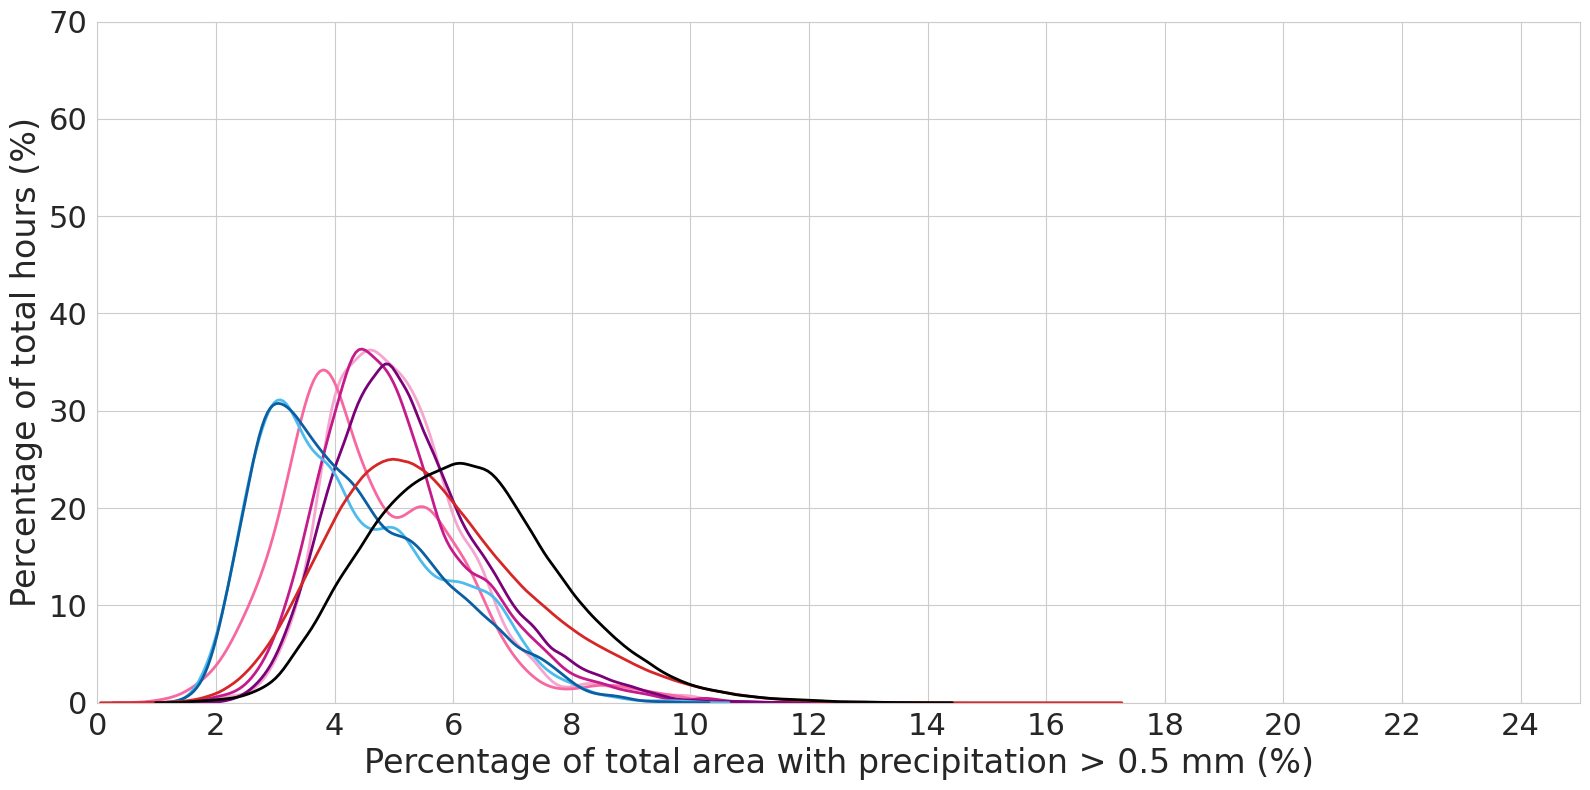

In [27]:
# 1) Common x-range + bin width
if mask == '01':
    xmin, xmax = 0, 35

elif mask == '02':
    xmin, xmax = 0, 25

elif mask == '05':
    xmin, xmax = 0, 25

elif mask == '1':
    xmin, xmax = 0, 60
bin_width  = 1.0
# 2) Your datasets
#datasets = [
#    (percent_ifs_on,    weights,     '#FF8C69', 'IFS_2.8_deep_on'),
#    (percent_ifs_off,   weights,     '#7FFF7F', 'IFS_2.8_deep_off'),
#    (percent_ifs_cycle3,weights,     '#6BB7EC', 'IFS_4.4-FESOM_5'),
#    (percent_ifs_cycle4,weights,     '#FF69B4', 'IFS_9-FESOM_5'),
#    (percent_icon_cycle3,weights,     '#C5A5CF80', 'ICON_5'),
#    (percent_cesm2,     weights_cesm2,'#FFC300','CESM2'),
#    (percent_imerg,     weights,     '#7E57C2', 'IMERG'),
#]


datasets = [
    # IFS group – range of magentas (light → dark)
    (percent_ifs_on,     weights_ifs_high,    '#F4A6CF', 'IFS_2.8_deep_on'),   # pale pink-magenta
    (percent_ifs_off,    weights_ifs_high,    '#F768A1', 'IFS_2.8_deep_off'),  # mid magenta
    (percent_ifs_cycle3, weights_ifs_cycle3,  '#C51B8A', 'IFS_4.4-FESOM_5'),   # strong magenta
    (percent_ifs_cycle4, weights_ifs_cycle4,  '#7A0177', 'IFS_9-FESOM_5'),     # deep magenta
    # ICON group – range of blues (light → dark)
    (percent_icon_cycle3, weights_icon_cycle3, '#4DBBEE', 'ICON_5'),           # sky blue
    (percent_icon_cycle4, weights_icon_cycle4, '#0A5FA3', 'ICON_9'),           # deep blue
    # CESM2-LE ensemble, all members pooled (masks '01', '05') – red
    (percent_cesm2,      weights_cesm2,       '#D62728', 'CESM2'),
    # IMERG – black
    (percent_imerg,      weights_imerg,       '#000000', 'IMERG'),
]
datasets = [d for d in datasets if d[0] is not None]     # no CESM2 for mask '1'




plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

# 3) Plot only the KDEs
for data_da, wts_da, color, label in datasets:
    # extract numpy
    x = data_da.values.ravel()
    w = wts_da.values.ravel() if hasattr(wts_da, 'values') else np.asarray(wts_da).ravel()
    # drop NaNs
    #mask_plot = ~np.isnan(x)
    #x, w = x[mask_plot], w[mask_plot]
    #print(label)
    #print(len(x))
    # normalize weights so area under curve = 1
    #w_norm = w 
  
    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=1.0,      # tweak for smoother / sharper
        clip=(xmin, xmax),
        common_norm=False,  # each curve normalizes to its own w_norm
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 5) Labels, limits, legend
if mask == '01':
    xl = 'Percentage of total area with precipitation > 0.1 mm (%)'
    ax.set_ylim(0, 30)
elif mask == '02':
    xl = 'Percentage of total area with precipitation > 0.2 mm (%)'
    ax.set_ylim(0, 70)
    # Force y-ticks to be whole numbers, and reduce their number by half
    #ymin, ymax = ax.get_ylim()
    #yticks = np.arange(ymin, ymax + 1, 4)  # step=2 gives roughly half as many ticks
    #ax.set_yticks(yticks)
    #ax.set_yticklabels([f'{int(y)}' for y in yticks])  # ensures no decimals

elif mask == '05':
    xl = 'Percentage of total area with precipitation > 0.5 mm (%)'
    ax.set_ylim(0, 70)
    # Force y-ticks to be whole numbers, and reduce their number by half
    #ymin, ymax = ax.get_ylim()
    #yticks = np.arange(ymin, ymax + 1, 4)  # step=2 gives roughly half as many ticks
    #ax.set_yticks(yticks)
    #ax.set_yticklabels([f'{int(y)}' for y in yticks])  # ensures no decimals

elif mask == '1':
    xl = 'Percentage of total area with precipitation > 1 mm (%)'
    ax.set_ylim(0, 5)

plt.xlabel(xl, fontsize=24)
if mask == '1':
    plt.ylabel('Percentage of total days (%)', fontsize=24)
else:
    plt.ylabel('Percentage of total hours (%)', fontsize=24)

plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 2)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
#plt.legend(
#    legend_handles,
#    legend_labels,
#    loc='upper right',
#    prop={'size': 22},
#    bbox_to_anchor=(1.0, 1.0),
#    handlelength=2.5  # longer lines in legend if you like
#)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_sea_all_histo_precip_coverage_'+mask+'_new'
            +('_CESM2ens' if percent_cesm2 is not None else '')+'.pdf', format='pdf',bbox_inches='tight')

plt.show()